# 03 · Simulations: peeking, many arms, and the winner's curse

Notebook 02 found three ways real headline tests go wrong. Simulation lets us isolate each one, because the truth is known by construction. Every simulation is calibrated to a *typical* Upworthy test as measured in notebook 02: baseline CTR around 1%, about 3,200 impressions per arm, and a standard deviation of true headline effects of about 0.32 on the log-odds scale.

1. **Peeking:** checking a running test repeatedly and stopping at the first "significant" result, under both frequentist and Bayesian rules
2. **Many arms:** family-wise error and power as the number of headlines grows, under each correction
3. **Winner's curse:** type M (exaggeration) and type S (wrong-sign) errors as a function of sample size
4. **What a well-designed test would need:** sample-size planning that accounts for all of the above

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abtest import simulate as sim, power, plotting as P, provenance

P.apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

with open("../reports/results/02_portfolio.json") as f:
    portfolio = json.load(f)
P0 = round(portfolio["median_ctr_c"], 4)
N_ARM = int(round(portfolio["median_n_arm"], -2))
TAU = portfolio["tau_net"]
PHI = portfolio["phi"]
print(f"Typical test: baseline CTR {P0:.2%}, {N_ARM:,} impressions per arm, true-effect SD tau = {TAU:.3f}, A/A variance inflation phi = {PHI:.2f}")
RESULTS = {"p0": P0, "n_arm": N_ARM, "tau": TAU}

Typical test: baseline CTR 1.04%, 3,200 impressions per arm, true-effect SD tau = 0.323, A/A variance inflation phi = 1.67


## 1 · Peeking

An analyst launches an A/A test, where both arms are identical, and checks the dashboard after every 200 impressions per arm until each arm reaches about twice a typical test's traffic. The analyst stops as soon as the result looks significant. Three stopping rules are compared:

- **z-test, p < 0.05 at any look.** The classic mistake.
- **Bayesian, P(B > A) > 95% or < 5% at any look.** Often claimed to be "immune to peeking". It is not, if you use it as a stopping rule with a fixed threshold.
- **Pocock boundary.** A group-sequential design that spends α across the planned looks by using a stricter per-look threshold.

In [2]:
peek, pocock_alpha = sim.peeking(p=P0, n_max=2 * N_ARM, look_every=200, n_sims=40_000)
final = peek.iloc[-1]
print(f"{len(peek)} looks; Pocock nominal per-look alpha = {pocock_alpha:.4f}")
for col in peek.columns[2:]:
    print(f"  {col:<36} false-positive rate after all looks: {final[col]:.1%}")
RESULTS.update(peek_looks=len(peek), pocock_alpha=pocock_alpha,
               peek_fpr={c: final[c] for c in peek.columns[2:]})

32 looks; Pocock nominal per-look alpha = 0.0061
  z-test, stop when p < 0.05           false-positive rate after all looks: 27.5%
  Bayesian, stop when P(B>A) > 95%     false-positive rate after all looks: 41.8%
  Pocock boundary (corrected)          false-positive rate after all looks: 3.9%


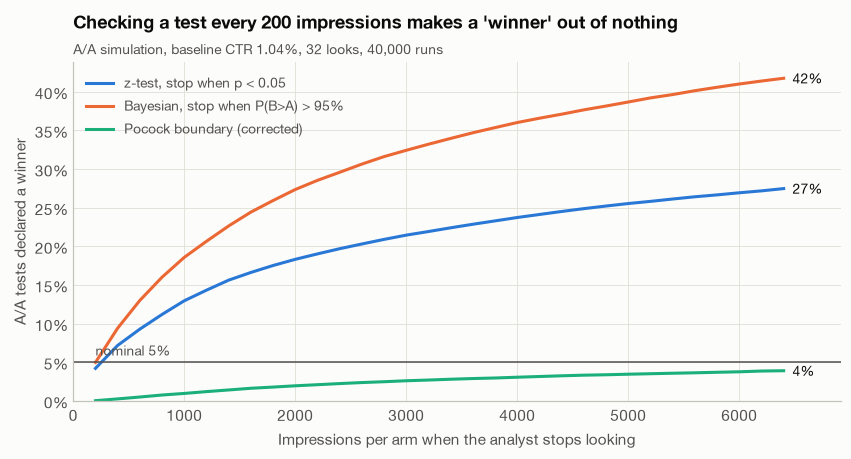

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(peek.columns[2:], [P.BLUE, P.ORANGE, P.AQUA]):
    ax.plot(peek["n_per_arm"], peek[col], color=color, label=col)
    ax.text(peek["n_per_arm"].iloc[-1] + 80, peek[col].iloc[-1], f"{peek[col].iloc[-1]:.0%}",
            va="center", color=P.INK, fontsize=9)
ax.axhline(0.05, color=P.INK_2, lw=1)
ax.text(peek["n_per_arm"].iloc[0], 0.055, "nominal 5%", color=P.INK_2, fontsize=9, va="bottom")
ax.set_xlim(0, peek["n_per_arm"].iloc[-1] * 1.08)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Impressions per arm when the analyst stops looking")
ax.set_ylabel("A/A tests declared a winner")
ax.legend(loc="upper left")
ax.set_title("Checking a test every 200 impressions makes a 'winner' out of nothing")
P.subtitle(ax, f"A/A simulation, baseline CTR {P0:.2%}, {len(peek)} looks, 40,000 runs")
P.save(fig, "11_peeking")
plt.show()

## 2 · More headlines, more false winners, less power

Upworthy tests usually had 4–6 headlines. Below, arm 0 is the control. In the **null** scenario every treatment equals control. In the **one real winner** scenario, arm 1 has a true +80% lift (roughly the typical test's MDE) and every other treatment is a dud.

In [4]:
null = sim.multiple_arms(k_values=range(2, 11), p=P0, n=N_ARM, true_lift=0.0, n_sims=40_000)
alt = sim.multiple_arms(k_values=range(2, 11), p=P0, n=N_ARM, true_lift=0.8, n_sims=40_000)
RESULTS["fwer_6_arms"] = null[null.arms == 6].set_index("method")["fwer"].to_dict()
RESULTS["power_6_arms"] = alt[alt.arms == 6].set_index("method")["power"].to_dict()
display(null.pivot(index="arms", columns="method", values="fwer").round(3))
alt.pivot(index="arms", columns="method", values="power").round(3)

method,Benjamini-Hochberg,Bonferroni,Holm,No correction
arms,,,,
2,0.0480,0.0480,0.0480,0.0480
3,0.0470,0.0450,0.0450,0.0910
4,0.0490,0.0460,0.0460,0.1280
5,0.0470,0.0440,0.0440,0.1550
6,0.0430,0.0400,0.0400,0.1810
7,0.0450,0.0410,0.0410,0.2110
8,0.0420,0.0390,0.0390,0.2320
9,0.0410,0.0370,0.0370,0.2510
10,0.0400,0.0360,0.0360,0.2650


method,Benjamini-Hochberg,Bonferroni,Holm,No correction
arms,,,,
2,0.7990,0.7990,0.7990,0.7990
3,0.7130,0.7100,0.7120,0.7990
4,0.6590,0.6550,0.6560,0.7980
5,0.6220,0.6190,0.6190,0.8010
6,0.5920,0.5880,0.5890,0.8000
7,0.5580,0.5540,0.5540,0.7950
8,0.5430,0.5400,0.5400,0.8000
9,0.5180,0.5150,0.5150,0.7940
10,0.5020,0.4990,0.5000,0.7990


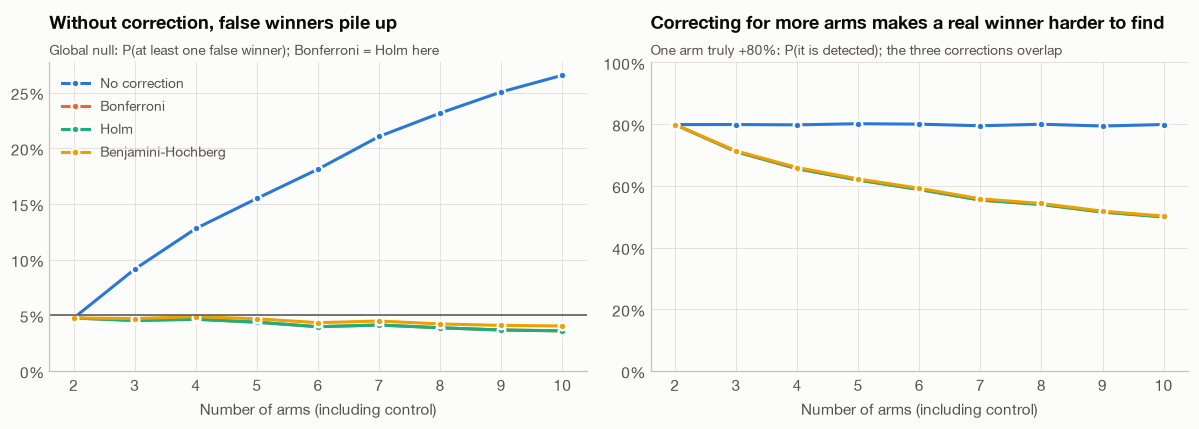

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = ["No correction", "Bonferroni", "Holm", "Benjamini-Hochberg"]
colors = dict(zip(order, [P.BLUE, P.ORANGE, P.AQUA, P.YELLOW]))
for ax, frame, col, title, sub in [
    (axes[0], null, "fwer", "Without correction, false winners pile up", "Global null: P(at least one false winner); Bonferroni = Holm here"),
    (axes[1], alt, "power", "Correcting for more arms makes a real winner harder to find", "One arm truly +80%: P(it is detected); the three corrections overlap"),
]:
    for m in order:
        d = frame[frame.method == m]
        ax.plot(d["arms"], d[col], color=colors[m], marker="o", ms=5, mec=P.SURFACE, mew=1.5, label=m)
    ax.set_xlabel("Number of arms (including control)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(title)
    P.subtitle(ax, sub)
axes[0].axhline(0.05, color=P.INK_2, lw=1)
axes[0].set_ylim(0, None)
axes[1].set_ylim(0, 1)
axes[0].legend(loc="upper left")
fig.tight_layout()
P.save(fig, "12_multiple_arms")
plt.show()

Under the global null, Bonferroni and Holm make *identical* "any winner?" decisions, because Holm's first step is Bonferroni. Holm's advantage only appears once something is real and it can step down to reject more. In a single test with few arms that advantage is small. BH controls the false discovery rate rather than the family-wise rate, so it is the most powerful of the three. It is the right tool for screening many ideas and the wrong one for a single irreversible ship decision.

## 3 · Winner's curse: type M and type S errors

Draw true headline effects from N(0, τ²) with τ from notebook 02, run two-arm tests of different sizes, and look **only at the significant ones**, which are the ones that get reported:

- **Exaggeration ratio (type M):** median |estimate| / |truth| among significant results
- **Type S rate:** share of significant results whose sign is wrong

In [6]:
rows = []
for n in [500, 1000, 2000, N_ARM, 5000, 10_000, 20_000, 50_000, 100_000, 200_000]:
    w = sim.winners_curse(p0=P0, n=n, tau=TAU, n_sims=200_000, seed=11)
    s = w[w.sig & (w.true != 0)]
    rows.append({"n_per_arm": n, "power (share significant)": w.sig.mean(),
                 "exaggeration (median)": np.median(np.abs(s.est) / np.abs(s.true)),
                 "type S rate": np.mean(np.sign(s.est) != np.sign(s.true))})
curse = pd.DataFrame(rows)
typical = curse[curse.n_per_arm == N_ARM].iloc[0]
RESULTS.update(exaggeration_typical=typical["exaggeration (median)"], type_s_typical=typical["type S rate"],
               share_sig_typical=typical["power (share significant)"])
curse

,n_per_arm,power (share significant),exaggeration (median),type S rate
0,500,0.0722,5.5282,0.1422
1,1000,0.1158,3.1064,0.0792
2,2000,0.1713,1.9901,0.0387
3,3200,0.2331,1.6079,0.0236
4,5000,0.3050,1.3851,0.0150
5,10000,0.4352,1.1943,0.0073
6,20000,0.5653,1.0953,0.0039
7,50000,0.7075,1.0381,0.0018
8,100000,0.7892,1.0186,0.0012
9,200000,0.8501,1.0098,0.0008


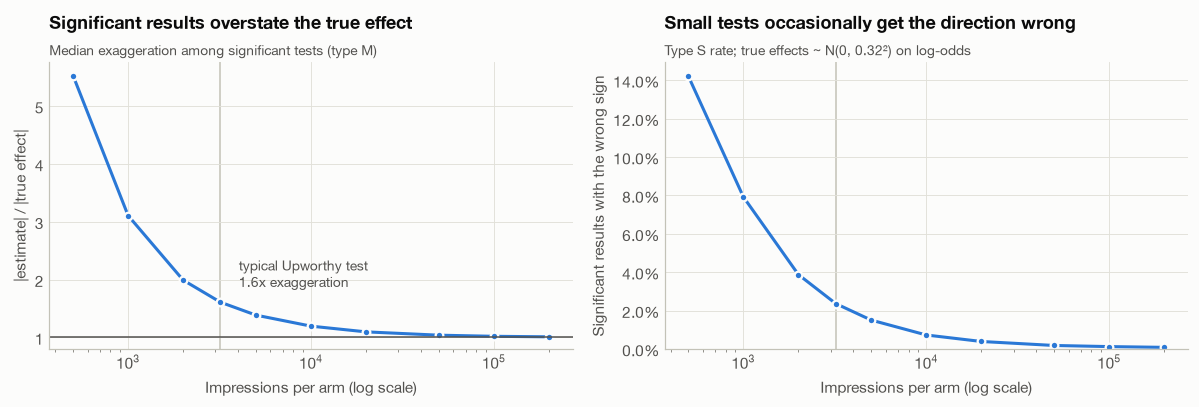

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(curse.n_per_arm, curse["exaggeration (median)"], color=P.BLUE, marker="o", ms=5, mec=P.SURFACE, mew=1.5)
ax.axhline(1, color=P.INK_2, lw=1)
ax.axvline(N_ARM, color=P.AXIS, lw=1, zorder=0)
ax.annotate(f"typical Upworthy test\n{typical['exaggeration (median)']:.1f}x exaggeration",
            (N_ARM, typical["exaggeration (median)"]), xytext=(12, 10), textcoords="offset points",
            color=P.INK_2, fontsize=9)
ax.set_xscale("log")
ax.set_ylim(0.8, None)
ax.set_xlabel("Impressions per arm (log scale)")
ax.set_ylabel("|estimate| / |true effect|")
ax.set_title("Significant results overstate the true effect")
P.subtitle(ax, "Median exaggeration among significant tests (type M)")

ax = axes[1]
ax.plot(curse.n_per_arm, curse["type S rate"], color=P.BLUE, marker="o", ms=5, mec=P.SURFACE, mew=1.5)
ax.axvline(N_ARM, color=P.AXIS, lw=1, zorder=0)
ax.set_xscale("log")
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_xlabel("Impressions per arm (log scale)")
ax.set_ylabel("Significant results with the wrong sign")
ax.set_title("Small tests occasionally get the direction wrong")
P.subtitle(ax, f"Type S rate; true effects ~ N(0, {TAU:.2f}²) on log-odds")
fig.tight_layout()
P.save(fig, "13_winners_curse_sim")
plt.show()

## 4 · Planning a test that would actually work

Combine everything: a realistic target lift, Bonferroni α for 4 challengers, 80% power, and the A/A variance inflation φ from notebook 02. φ effectively shrinks each impression's information by a factor of φ, so the impressions needed grow by φ.

In [8]:
rows = []
for lift in [0.05, 0.10, 0.20, round(np.expm1(TAU), 2)]:
    n_basic = power.sample_size_per_arm(P0, lift)
    n_bonf = power.sample_size_per_arm(P0, lift, alpha=0.05 / 4)
    rows.append({"target lift": f"{lift:+.0%}", "per arm (α=0.05)": n_basic,
                 "per arm (Bonferroni, 4 challengers)": n_bonf,
                 "per arm (+ A/A calibration)": int(np.ceil(n_bonf * PHI)),
                 "total, 5 arms": int(np.ceil(n_bonf * PHI)) * 5,
                 "x typical test": n_bonf * PHI / N_ARM})
plan = pd.DataFrame(rows)
RESULTS["plan"] = plan.to_dict(orient="records")
plan.style.format({c: "{:,.0f}" for c in plan.columns[1:-1]} | {"x typical test": "{:,.1f}x"})

,target lift,per arm (α=0.05),"per arm (Bonferroni, 4 challengers)",per arm (+ A/A calibration),"total, 5 arms",x typical test
0,+5%,"612,166","869,721","1,451,806","7,259,030",453.7x
1,+10%,"156,668","222,583","371,553","1,857,765",116.1x
2,+20%,"40,950","58,178","97,116","485,580",30.3x
3,+38%,"12,207","17,343","28,951","144,755",9.0x


**Design lessons for a headline-testing program**

1. **Fix the horizon, or use a sequential design.** Peeking with a fixed threshold turns a 5% error rate into several times that, and a Bayesian threshold does not change this. If you need to stop early, plan the looks (Pocock / O'Brien–Fleming / alpha-spending) or use always-valid methods.
2. **Test fewer headlines, or correct for many.** Each extra arm splits the traffic and adds another chance of a false win.
3. **Size tests for realistic effects.** Detecting a typical true headline effect (about ±38%) with Bonferroni correction and A/A calibration takes about 9× a typical Upworthy test's traffic. A ±10% refinement takes over 100×. At typical sizes, a "significant" winner overstates its true effect by about 1.6× (median), and about 2% of significant results point the wrong way.
4. **Shrink before you announce.** Report empirical-Bayes or otherwise regularized lifts, not raw winning lifts.

In [9]:
with open("../reports/results/03_simulations.json", "w") as f:
    json.dump({**RESULTS, "provenance": provenance.collect(samples=(), seeds={"peeking": 1, "multiple_arms": 2, "winners_curse": 11})}, f, indent=2, default=float)